In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import os
from scipy.optimize import fsolve
from scipy.optimize import root_scalar
from scipy.optimize import approx_fprime
from scipy.optimize import root
from scipy.signal import argrelextrema
import numdifftools as nd
from matplotlib import colormaps
import warnings
plt.rcParams["figure.dpi"] = 120

In [2]:
m_s = 100
m_B = 939
muK = np.linspace(-90,90,50)
muB = np.linspace(980, 1050,50)
muK_grid, muB_grid = np.meshgrid(muK, muB)

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2)

def PQM(muB, muK, B):
    return ((muB/3 + muK/2)**4 + (muB/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB/3 - muK/2, m_s) - B
    
def PNM(muB):
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B)

def extract_contour_coords(X, Y, Z, level):
    fig, ax = plt.subplots()
    contour_obj = ax.contour(X, Y, Z, levels=[level])
    # Directly access the paths from the contour object
    paths = []
    for c in contour_obj.get_paths():
        paths.append(c.vertices)
    plt.close(fig)  # Close the plot if you only want data
    if not paths:
        raise RuntimeError(f"No contours found at level {level}")
    return paths[0][:, 0], paths[0][:, 1]

def aQstar_and_other_stuff(muB, muK, P_crit, Delta_P):  # the muB should be understood as muB_Qstar, and same for muK
    # calculate nB_Qstar, nK_Qstar using partial derivitives
    Qstar = np.array([muB, muK])
    grad_Qstar = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]

    # solve for muB_Q
    PQM_at_Q = lambda x: PQM(x, 0, B) - P_crit - Delta_P
    muB_Q = fsolve(PQM_at_Q, 1050)[0]  # 1050 is the starting point of numerical root finding

    # calculate nB_Q and nK_Q using partial derivitives
    Q = np.array([muB_Q, 0])  # the point Q
    grad_Q = approx_fprime(Q, PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]

    return (nK_Qstar - nK_Q)/nB_Q , nB_Q, muB_Q

In [3]:
# --- Function to compute P and mu_B given k_F ---
def PNM_Walecka(k_F):
    # Equation to solve: Eq3 for sigma_bar
    def eq3_sigma(sigma_bar):
        m_star = m_N - g_sigma * sigma_bar
        if m_star <= 0:
            return 1e6
        E_F = np.sqrt(k_F**2 + m_star**2)
        log_arg = (k_F + E_F) / m_star
        if log_arg <= 0:
            return 1e6
        scalar_term = k_F * E_F - m_star**2 * np.log(log_arg)
        rhs = (g_sigma / m_sigma**2) * m_star * scalar_term / (np.pi**2)
        return -sigma_bar + rhs

    # Solve for sigma_bar
    sigma_bar = fsolve(eq3_sigma, 0.02, xtol=1e-10)[0]
    m_star = m_N - g_sigma * sigma_bar

    # Compute omega_0_bar
    omega_0_bar = (g_omega / m_omega**2) * (2 * k_F**3) / (3 * np.pi**2)

    # Compute effective Fermi energy
    E_F_star = np.sqrt(k_F**2 + m_star**2)

    # Compute true baryon chemical potential
    mu_B = E_F_star + g_omega * omega_0_bar

    # Compute pressure
    term1 = 0.5 * m_omega**2 * omega_0_bar**2
    term2 = 0.5 * m_sigma**2 * sigma_bar**2
    term3 = ((2/3) * k_F**3 - m_star**2 * k_F) * E_F_star
    term4 = m_star**4 * np.log((k_F + E_F_star) / m_star)
    kinetic_term = (term3 + term4) / (4 * np.pi**2)

    pressure = term1 - term2 + kinetic_term

    return pressure, mu_B

# Prior to 16 June

A small question: the merger doesn't have spherical symmetry, so why can we still assume the $i,j,k$ components of Lorentz index for rho meson mean field vanish?

#### $QMC-RMFx$ models for NM

$$
\begin{aligned}
P = & -\frac{1}{2}m_\sigma^2\langle\sigma\rangle^2 - \frac{bM}{3}\left(g_\sigma\langle\sigma\rangle\right)^3 - \frac{c}{4}\left(g_\sigma\langle\sigma\rangle\right)^4 + \frac{1}{2}m_\omega^2\langle\omega_0\rangle^2 + \frac{1}{2}m_\rho^2\langle\rho_{0,3}\rangle^2 + b_1 g_\rho^2\langle\omega_0\rangle^2\langle\rho_{0,3}\rangle^2 \\
& + \frac{1}{8\pi^2} \left[ 
\left( \frac{2}{3} k_{F,p}^3 - (m_N^*)^2 k_{F,p} \right) E_{F,p}^* 
+ (m_N^*)^4 \ln \left( \frac{k_{F,p} + E_{F,p}^*}{m_N^*} \right) 
\right] \\
& +  \frac{1}{8\pi^2} \left[ 
\left( \frac{2}{3} k_{F,n}^3 - (m_N^*)^2 k_{F,n} \right) E_{F,n}^* 
+ (m_N^*)^4 \ln \left( \frac{k_{F,n} + E_{F,n}^*}{m_N^*} \right) 
\right] \\
& + \frac{k_{F,p}^4}{12\pi^2} + B
\end{aligned}
$$

$$
m^*_N = m_N - g_\sigma\langle\sigma\rangle
$$
$$
E^*_{F,p} = \mu_p - g_\omega\langle\omega_0\rangle - \frac{g_\rho}{2}\langle\rho_{0,3}\rangle = \sqrt{k_{F,p}^2 + (m_N^*)^2}
$$
$$
E^*_{F,n} = \mu_n - g_\omega\langle\omega_0\rangle + \frac{g_\rho}{2}\langle\rho_{0,3}\rangle = \sqrt{k_{F,n}^2 + (m_N^*)^2}
$$

$$
\begin{aligned}
& n_n = \frac{k_{F,n}^3}{3\pi^2}\;,\quad n_p = \frac{k_{F,p}^3}{3\pi^2}\;,\quad k_{F,n} = 2k_{F,p} \\
& n_{sn} = \frac{m_N^*}{2\pi^2} \left[ k_{F,n} E^*_{F,n} - (m_N^*)^2 \ln \left( \frac{k_{F,n} + E^*_{F,n}}{m_N^*} \right) \right] \\
& n_{sp} = \frac{m_N^*}{2\pi^2} \left[ k_{F,p} E^*_{F,p} - (m_N^*)^2 \ln \left( \frac{k_{F,p} + E^*_{F,p}}{m_N^*} \right) \right]
\end{aligned}
$$

$$
\left\{
\begin{aligned}
\begin{align}
m_\sigma^2 \langle \sigma \rangle &= g_\sigma (n_{sn} + n_{sp}) - b M g_\sigma^3 \langle \sigma \rangle^2 - c g_\sigma^4 \langle \sigma \rangle^3 \\
m_\omega^2 \langle \omega_0 \rangle &= g_\omega (n_n + n_p) - 2 b_1 g_\rho^2 \langle \rho_{03} \rangle^2 \langle \omega_0 \rangle \\
m_\rho^2 \langle \rho_{03} \rangle &= \frac{1}{2} g_\rho (n_p - n_n) - 2 b_1 g_\rho^2 \langle \rho_{03} \rangle \langle \omega_0 \rangle^2
\end{align}
\end{aligned}
\right.
$$

$QMC-RMF3$

In [4]:
import numpy as np
from scipy.optimize import fsolve

# Constants
m_N = 939  # MeV
m_sigma = 491.5  # MeV
m_omega = 782.5  # MeV
m_rho = 763.0  # MeV
k_F_p = 200  # MeV
k_F_n = 2 * k_F_p
k_F_e = k_F_p

# Coupling constants
g_sigma = 8.32
g_omega = 9.76
g_rho = 11.02
b = 0.0063
c = -0.006
b1 = 5.87
M = m_N
B = -206742

# Define the system of equations
def equations(vars):
    sigma, omega0, rho03 = vars

    m_star = m_N - g_sigma * sigma

    # Effective Fermi energies
    E_F_p_star = np.sqrt(k_F_p**2 + m_star**2)
    E_F_n_star = np.sqrt(k_F_n**2 + m_star**2)

    # Scalar densities
    log_arg_p = (k_F_p + E_F_p_star) / m_star
    log_arg_n = (k_F_n + E_F_n_star) / m_star

    n_sp = (m_star / (2 * np.pi**2)) * (k_F_p * E_F_p_star - m_star**2 * np.log(log_arg_p))
    n_sn = (m_star / (2 * np.pi**2)) * (k_F_n * E_F_n_star - m_star**2 * np.log(log_arg_n))

    # Number densities
    n_p = k_F_p**3 / (3 * np.pi**2)
    n_n = k_F_n**3 / (3 * np.pi**2)

    # Equations
    eq1_lhs = m_sigma**2 * sigma
    eq1_rhs = g_sigma * (n_sp + n_sn) - b * M * g_sigma**3 * sigma**2 - c * g_sigma**4 * sigma**3

    eq2_lhs = m_omega**2 * omega0
    eq2_rhs = g_omega * (n_n + n_p) - 2 * b1 * g_rho**2 * rho03**2 * omega0

    eq3_lhs = m_rho**2 * rho03
    eq3_rhs = 0.5 * g_rho * (n_p - n_n) - 2 * b1 * g_rho**2 * rho03 * omega0**2

    return [eq1_lhs - eq1_rhs, eq2_lhs - eq2_rhs, eq3_lhs - eq3_rhs]

# Initial guess
initial_guess = [0.1, 0.1, 0.1]

# Solve the system
solution = fsolve(equations, initial_guess)
sigma_sol, omega0_sol, rho03_sol = solution

# Evaluate residuals
residuals = equations(solution)
relative_errors = [abs(res / lhs) if lhs != 0 else np.nan for res, lhs in zip(residuals, [m_N**2 * sigma_sol, m_N**2 * omega0_sol, m_N**2 * rho03_sol])]

# Nicely format and print the results
print("=== Mean Field Solutions ===")
print(f"<σ>       = {sigma_sol:.6f} MeV")
print(f"<ω₀>      = {omega0_sol:.6f} MeV")
print(f"<ρ₀₃>     = {rho03_sol:.6f} MeV\n")

print("=== Relative Residuals (|lhs - rhs| / lhs) ===")
print(f"Equation 1 (σ):     {relative_errors[0]:.2e}")
print(f"Equation 2 (ω₀):    {relative_errors[1]:.2e}")
print(f"Equation 3 (ρ₀₃):   {relative_errors[2]:.2e}")

=== Mean Field Solutions ===
<σ>       = 51.639497 MeV
<ω₀>      = 37.330448 MeV
<ρ₀₃>     = -4.056552 MeV

=== Relative Residuals (|lhs - rhs| / lhs) ===
Equation 1 (σ):     2.97e-12
Equation 2 (ω₀):    6.50e-12
Equation 3 (ρ₀₃):   2.42e-10


In [5]:
# Define the updated function to compute mean fields and use them dynamically
def PNM_qmc3(k_F):
    k_F = float(np.atleast_1d(k_F)[0]) 
    # Constants
    m_N = 939  # MeV
    m_sigma = 491.5  # MeV
    m_omega = 782.5  # MeV
    m_rho = 763.0  # MeV
    g_sigma = 8.32
    g_omega = 9.76
    g_rho = 11.02
    b = 0.0063
    c = -0.006
    b1 = 5.87
    M = m_N
    B_qmc3 = -206742
    M = 939
    k_F_p = k_F
    k_F_n = 2 * k_F

    # Define the system of equations for mean fields
    def equations(vars):
        sigma, omega0, rho03 = vars
        m_star = m_N - g_sigma * sigma

        E_F_p_star = np.sqrt(k_F_p**2 + m_star**2)
        E_F_n_star = np.sqrt(k_F_n**2 + m_star**2)

        log_arg_p = (k_F_p + E_F_p_star) / m_star
        log_arg_n = (k_F_n + E_F_n_star) / m_star

        n_sp = (m_star / (2 * np.pi**2)) * (k_F_p * E_F_p_star - m_star**2 * np.log(log_arg_p))
        n_sn = (m_star / (2 * np.pi**2)) * (k_F_n * E_F_n_star - m_star**2 * np.log(log_arg_n))

        n_p = k_F_p**3 / (3 * np.pi**2)
        n_n = k_F_n**3 / (3 * np.pi**2)

        eq1 = m_sigma**2 * sigma - g_sigma * (n_sp + n_sn) + b * M * g_sigma**3 * sigma**2 + c * g_sigma**4 * sigma**3
        eq2 = m_omega**2 * omega0 - g_omega * (n_n + n_p) + 2 * b1 * g_rho**2 * rho03**2 * omega0
        eq3 = m_rho**2 * rho03 - 0.5 * g_rho * (n_p - n_n) + 2 * b1 * g_rho**2 * rho03 * omega0**2

        return [eq1, eq2, eq3]

    # Solve for mean fields
    sigma_sol, omega0_sol, rho03_sol = fsolve(equations, [0.1, 0.1, 0.1])

    m_star = m_N - g_sigma * sigma_sol
    E_F_p_star = np.sqrt(k_F_p**2 + m_star**2)
    E_F_n_star = np.sqrt(k_F_n**2 + m_star**2)

    # Chemical potentials
    mu_p = E_F_p_star + g_omega * omega0_sol + 0.5 * g_rho * rho03_sol
    mu_n = E_F_n_star + g_omega * omega0_sol - 0.5 * g_rho * rho03_sol
    mu_e = k_F_e

    # Number densities
    n_p = k_F_p**3 / (3 * np.pi**2)
    n_n = k_F_n**3 / (3 * np.pi**2)
    n_B = n_p + n_n

    # Baryon chemical potential (density-weighted)
    mu_B = (mu_p * n_p + mu_n * n_n) / n_B  # (mu_p + mu_n)/2

    #print(mu_p + mu_e - mu_n)

    # Pressure calculation
    term_sigma = -0.5 * m_sigma**2 * sigma_sol**2 - (b * M / 3) * (g_sigma * sigma_sol)**3 - (c / 4) * (g_sigma * sigma_sol)**4
    term_omega = 0.5 * m_omega**2 * omega0_sol**2
    term_rho = 0.5 * m_rho**2 * rho03_sol**2 + b1 * g_rho**2 * omega0_sol**2 * rho03_sol**2

    term_fermi_p = (1 / (8 * np.pi**2)) * ( ((2 / 3)*k_F_p**3 - m_star**2 * k_F_p) * E_F_p_star +
                  m_star**4 * np.log((k_F_p + E_F_p_star) / m_star))

    term_fermi_n = (1 / (8 * np.pi**2)) * ( ((2 / 3)*k_F_n**3 - m_star**2 * k_F_n) * E_F_n_star +
                  m_star**4 * np.log((k_F_n + E_F_n_star) / m_star))

    term_electron = k_F_p**4 / (12 * np.pi**2)

    P = term_sigma + term_omega + term_rho + term_fermi_p + term_fermi_n + term_electron + B_qmc3

    return P, mu_B

# Evaluate at k_F = 200 MeV
P_dynamic, mu_B_dynamic = PNM_qmc3(200)
P_dynamic, mu_B_dynamic

(np.float64(151265598.9130001), np.float64(1018.2181544165398))

In [6]:
from scipy.optimize import fsolve
import numpy as np

# error safe
def PNM_qmc1(k_F):
    k_F = float(np.atleast_1d(k_F)[0])  # Ensure scalar input

    # Constants
    m_N = 939  # MeV
    m_sigma = 491.5  # MeV
    m_omega = 782.5  # MeV
    m_rho = 763.0  # MeV
    g_sigma = 7.54
    g_omega = 8.43
    g_rho = 10.88
    b = 0.0073
    c = 0.0035
    b1 = 7.89
    B_qmc1 = -612215  # MeV^4
    M = 939
    k_F_p = k_F
    k_F_n = 2 * k_F

    # Define the system of equations for mean fields
    def equations(vars):
        sigma, omega0, rho03 = vars
        m_star = m_N - g_sigma * sigma

        E_F_p_star = np.sqrt(k_F_p**2 + m_star**2)
        E_F_n_star = np.sqrt(k_F_n**2 + m_star**2)

        # Prevent invalid log arguments
        log_arg_p = max((k_F_p + E_F_p_star) / max(m_star, 1e-8), 1e-8)
        log_arg_n = max((k_F_n + E_F_n_star) / max(m_star, 1e-8), 1e-8)

        n_sp = (m_star / (2 * np.pi**2)) * (k_F_p * E_F_p_star - m_star**2 * np.log(log_arg_p))
        n_sn = (m_star / (2 * np.pi**2)) * (k_F_n * E_F_n_star - m_star**2 * np.log(log_arg_n))

        n_p = k_F_p**3 / (3 * np.pi**2)
        n_n = k_F_n**3 / (3 * np.pi**2)

        eq1 = m_sigma**2 * sigma - g_sigma * (n_sp + n_sn) + b * M * g_sigma**3 * sigma**2 + c * g_sigma**4 * sigma**3
        eq2 = m_omega**2 * omega0 - g_omega * (n_n + n_p) + 2 * b1 * g_rho**2 * rho03**2 * omega0
        eq3 = m_rho**2 * rho03 - 0.5 * g_rho * (n_p - n_n) + 2 * b1 * g_rho**2 * rho03 * omega0**2

        return [eq1, eq2, eq3]

    # Solve for mean fields safely
    sol, info, ier, msg = fsolve(equations, [0.1, 0.1, 0.1], full_output=True)
    if ier != 1:
        return np.nan, np.nan  # If solver fails, return NaN

    sigma_sol, omega0_sol, rho03_sol = sol

    m_star = m_N - g_sigma * sigma_sol
    E_F_p_star = np.sqrt(k_F_p**2 + m_star**2)
    E_F_n_star = np.sqrt(k_F_n**2 + m_star**2)

    # Chemical potentials
    mu_p = E_F_p_star + g_omega * omega0_sol + 0.5 * g_rho * rho03_sol
    mu_n = E_F_n_star + g_omega * omega0_sol - 0.5 * g_rho * rho03_sol

    # Number densities
    n_p = k_F_p**3 / (3 * np.pi**2)
    n_n = k_F_n**3 / (3 * np.pi**2)
    n_B = n_p + n_n

    # Baryon chemical potential (density-weighted)
    mu_B = (mu_p * n_p + mu_n * n_n) / n_B

    # Safe log arguments
    log_arg_p = max((k_F_p + E_F_p_star) / max(m_star, 1e-8), 1e-8)
    log_arg_n = max((k_F_n + E_F_n_star) / max(m_star, 1e-8), 1e-8)

    # Pressure calculation
    term_sigma = -0.5 * m_sigma**2 * sigma_sol**2 - (b * M / 3) * (g_sigma * sigma_sol)**3 - (c / 4) * (g_sigma * sigma_sol)**4
    term_omega = 0.5 * m_omega**2 * omega0_sol**2
    term_rho = 0.5 * m_rho**2 * rho03_sol**2 + b1 * g_rho**2 * omega0_sol**2 * rho03_sol**2

    term_fermi_p = (1 / (8 * np.pi**2)) * (
        ((2 / 3) * k_F_p**3 - m_star**2 * k_F_p) * E_F_p_star +
        m_star**4 * np.log(log_arg_p)
    )

    term_fermi_n = (1 / (8 * np.pi**2)) * (
        ((2 / 3) * k_F_n**3 - m_star**2 * k_F_n) * E_F_n_star +
        m_star**4 * np.log(log_arg_n)
    )

    term_electron = k_F_p**4 / (12 * np.pi**2)

    P = term_sigma + term_omega + term_rho + term_fermi_p + term_fermi_n + term_electron + B_qmc1

    return P, mu_B

# Evaluate at k_F = 100 MeV
P_dynamic, mu_B_dynamic = PNM_qmc1(200)
P_dynamic, mu_B_dynamic

(np.float64(139002129.22592586), np.float64(1011.0384709332948))

151265598, 139002129

### some plotting

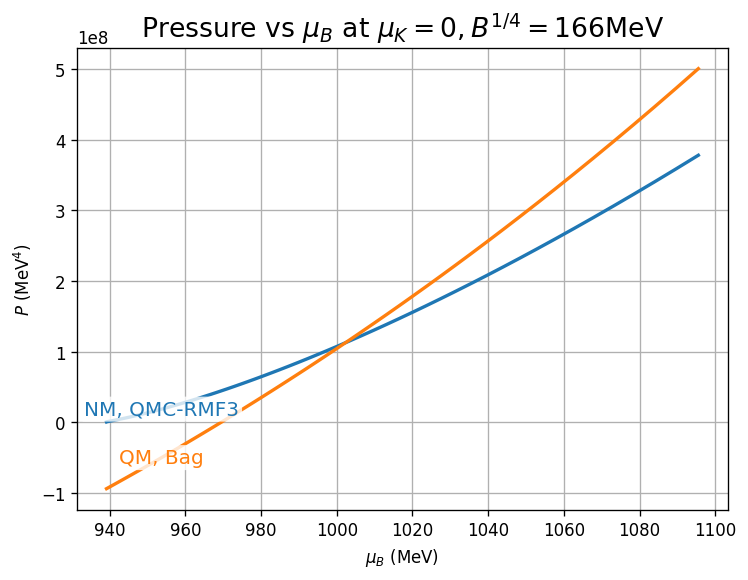

In [7]:
kF = np.linspace(100, 220, 100)  # 43

'''
P_nonint = []
muB_nonint = [] 
for k_F in kF:
    tmp1, tmp2 = PNM(k_F)
    P_nonint.append(tmp1)
    muB_nonint.append(tmp2)
'''

B_one_forth = 166
B = B_one_forth**4

P_qmc = []
muB_qmc = []
for k_F in kF:
    tmp1, tmp2 = PNM_qmc3(k_F)
    P_qmc.append(tmp1)
    muB_qmc.append(tmp2)
P_QM = PQM(np.array(muB_qmc), 0, B)

plt.figure(figsize=(7, 5))

#plt.plot(muB_W, [PNM_old(x) for x in muB_W], 'b')
plt.plot(muB_qmc, P_qmc, lw=2, color='tab:blue')
#plt.plot(np.linspace(910, 1010, 100), np.zeros(100), 'k')
plt.plot(muB_qmc, P_QM, lw=2, color='tab:orange')
plt.xlabel(r'$\mu_B$ (MeV)')
plt.ylabel(r'$P$ (MeV$^4$)')
#plt.text(980, 5e+6, "Non-interacting")
#plt.text(965, 8e+7, "Walecka")

boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(muB_qmc[50], P_qmc[50], "NM, QMC-RMF3", fontsize=12, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(muB_qmc[50],  PQM(muB_qmc[50], 0, B),  "QM, Bag", fontsize=12, color='tab:orange', ha='center', va='center', bbox=boxprops)

plt.title(r'Pressure vs $\mu_B$ at $\mu_K = 0, B^{1/4}=$'+str(B_one_forth)+'MeV', fontsize=16)
plt.grid(True)

1002.3055521863074


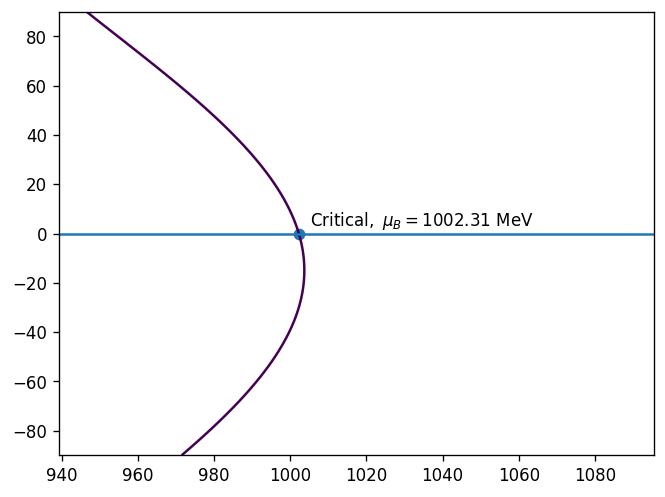

In [8]:
muK = np.linspace(-90,90,500)
kF = np.linspace(100, 220, 1000)

muB = []
P_NM = np.ones([len(kF), len(muK)])
for i in range(len(kF)):
    tmp1, tmp2 = PNM_qmc3(kF[i])
    muB.append(tmp2)
    for j in range(len(muK)):
        P_NM[i,j] = tmp1

muK_grid, muB_grid = np.meshgrid(muK, muB)
P_QM = PQM(muB_grid, muK_grid, B)

muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM - P_NM, level = 0)
min_ind = np.argmin(np.abs(muK_contour_coor))
muB_crit = muB_contour_coor[min_ind]
print(muB_crit)
P_crit = PQM(muB_crit, 0, B)

#PNM_minus_PShift = lambda x: PNM_qmc1(x)[0] - P_crit
#muB_crit = PNM_qmc1(fsolve(PNM_minus_PShift, 1050))[1]

plt.scatter(muB_crit,0) 
plt.text(muB_crit+3, 3, rf"$\mathrm{{Critical}},\ \mu_B = {muB_crit:.2f}\ \mathrm{{MeV}}$")

# rf"$N,\ \mu_B = {muB_N.item():.2f}\ \mathrm{{MeV}}$"
#muB_crit
#muB_crit = 978.8

contours = plt.contour(muB_grid, muK_grid, P_QM - P_NM, levels=[0])
#contours = plt.contour(muB_grid, muK_grid, P_QM, levels=[0])
plt.plot(muB, np.zeros(len(muB)))

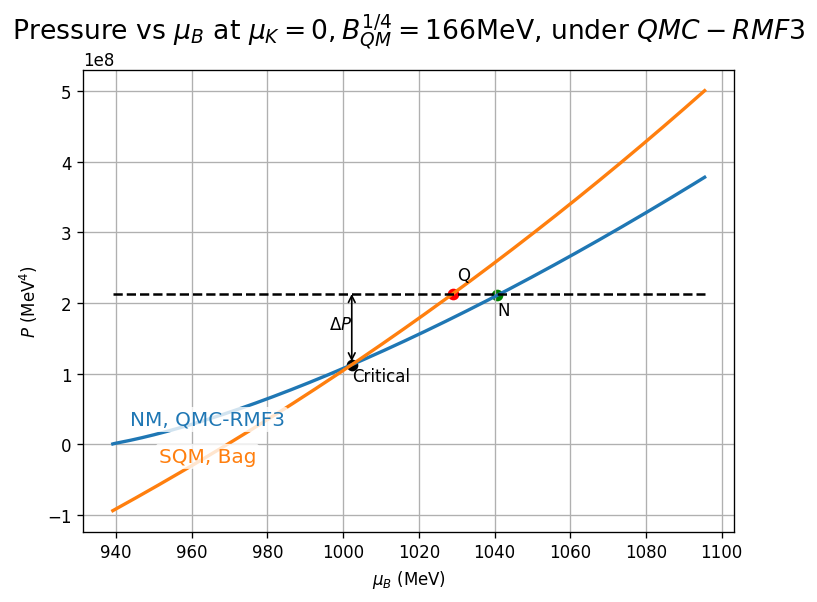

In [9]:
P_qmc = []
muB_qmc = []
for k_F in kF:
    tmp1, tmp2 = PNM_qmc3(k_F)
    P_qmc.append(tmp1)
    muB_qmc.append(tmp2)
P_QM_equ = PQM(np.array(muB_qmc), 0, B)

P_qmc = np.array(P_qmc)
muB_qmc = np.array(muB_qmc)

Delta_P = 1e+8

plt.figure(figsize=(7, 5))

#plt.plot(muB_W, [PNM_old(x) for x in muB_W], 'b')
plt.plot(muB_qmc, P_qmc, lw=2, color='tab:blue')
#plt.plot(np.linspace(910, 1010, 100), np.zeros(100), 'k')
plt.plot(muB_qmc, P_QM_equ, lw=2, color='tab:orange')
#plt.plot(muB_qmc, PNM_old(muB_qmc), lw=2, color='tab:green')
plt.xlabel(r'$\mu_B$ (MeV)')
plt.ylabel(r'$P$ (MeV$^4$)')
#plt.text(980, 5e+6, "Non-interacting")
#plt.text(965, 8e+7, "Walecka")

boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(muB_qmc[600], P_qmc[600], "NM, QMC-RMF3", fontsize=12, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(muB_qmc[600],  P_QM_equ[600],  "SQM, Bag", fontsize=12, color='tab:orange', ha='center', va='center', bbox=boxprops)
#plt.text(muB_qmc[860],  PNM_old(muB_W[860]),  "NM, non-int", fontsize=12, color='tab:green', ha='center', va='center', bbox=boxprops)

plt.scatter(muB_crit, P_crit, c='k') # 3.6e+7
plt.text(muB_crit, 0.8*P_crit, r"Critical")
plt.plot(muB, (P_crit + Delta_P)*np.ones(len(muB)), 'k--')

plt.scatter(1029, PQM(1029, 0, B), c='r')
plt.text(1030, PQM(1030,0,B)*1.07, r"Q")
P_tmp, muB_tmp = PNM_qmc3(207)
plt.scatter(muB_tmp, P_tmp, c='g')
plt.text(muB_tmp, 0.87*P_tmp, r"N")

plt.annotate(
    '', 
    xy=(muB_crit, P_crit), 
    xytext=(muB_crit, P_crit+Delta_P*1.05
           ),
    arrowprops=dict(arrowstyle='<->', color='black', lw=1.0),
)
# Optional label for the arrow
plt.text(muB_crit-6, (P_crit + Delta_P)/1.25, r'$\Delta P$', va='center')


plt.title(r'Pressure vs $\mu_B$ at $\mu_K = 0, B_{QM}^{1/4}=$'+str(B_one_forth)+'MeV'+r', under $QMC-RMF3$', fontsize=16)
plt.grid(True)

# Define the path to the Downloads folder
downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "QMC-RMF3-1.pdf"), dpi=300)

In [10]:
PNM_minus_PShift = lambda x: PNM_qmc1(x)[0] - P_crit - Delta_P
muB_N = PNM_qmc1(fsolve(PNM_minus_PShift, 150)[0])[1]
muB_N

np.float64(1038.1639668453865)

/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_30497/2129813937.py:32: RuntimeWarning: invalid value encountered in log
  n_sp = (m_star / (2 * np.pi**2)) * (k_F_p * E_F_p_star - m_star**2 * np.log(log_arg_p))
/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_30497/2129813937.py:33: RuntimeWarning: invalid value encountered in log
  n_sn = (m_star / (2 * np.pi**2)) * (k_F_n * E_F_n_star - m_star**2 * np.log(log_arg_n))


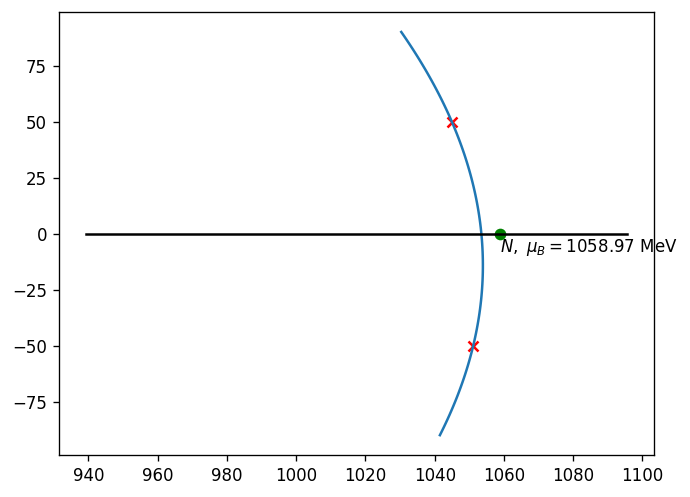

In [11]:
Delta_P = 2e+8
muK = np.linspace(-90,90,100)
kF = np.linspace(100, 220, 200)

muB = []
P_NM = np.ones([len(kF), len(muK)])
for i in range(len(kF)):
    tmp1, tmp2 = PNM_qmc3(kF[i])
    muB.append(tmp2)
    for j in range(len(muK)):
        P_NM[i,j] = tmp1

muK_grid, muB_grid = np.meshgrid(muK, muB)
P_QM = PQM(muB_grid, muK_grid, B)


# plot contour
muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
plt.plot(muB_contour_coor, muK_contour_coor)
plt.plot(muB, np.zeros(len(muB)), 'k')

# plotting N
PNM_minus_PShift = lambda x: PNM_qmc3(x)[0] - P_crit - Delta_P
muB_N = PNM_qmc1(fsolve(PNM_minus_PShift, 150))[1]
plt.scatter(muB_N,0, c='g')
plt.text(muB_N, -8, rf"$N,\ \mu_B = {muB_N.item():.2f}\ \mathrm{{MeV}}$")

# plotting cross
mu_average = []
epsilon = np.sqrt(np.finfo(float).eps)
for i in range(len(muB_contour_coor)):
    muB_Qstar = muB_contour_coor[i]
    muK_Qstar = muK_contour_coor[i]
    Qstar = np.array([muB_Qstar, muK_Qstar])
    grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
    nB_Qstar = grad[0]
    nK_Qstar = grad[1]
    mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
difference = np.abs(np.array(mu_average) - muB_N)
minima_ind = argrelextrema(difference, np.less)[0]

plt.scatter(muB_contour_coor[minima_ind[0]],muK_contour_coor[minima_ind[0]], marker='x', c='r')
plt.scatter(muB_contour_coor[minima_ind[1]],muK_contour_coor[minima_ind[1]], marker='x', c='r')

#plt.scatter(np.array([i for i in range(len(mu_average))]), mu_average, s=0.1)
#plt.plot(np.array([i for i in range(len(mu_average))]), muB_N*np.ones(len(mu_average)))

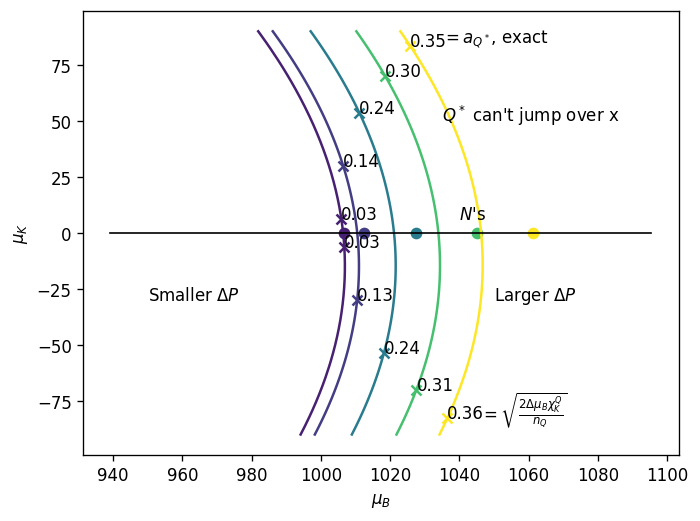

In [31]:
from scipy.signal import argrelextrema
from scipy.optimize import fsolve
import numdifftools as nd
from matplotlib import colormaps
cmap = colormaps['viridis']

Delta = np.array([1.5e+7, 3e+7, 7e+7, 1.2e+8, 1.7e+8]) #P_crit * np.array([0.1, 0.2, 0.3, 0.4, 0.5])

for Delta_P in Delta:
    muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
    mu_average = []
    for i in range(len(muB_contour_coor)):
        muB_Qstar = muB_contour_coor[i]
        muK_Qstar = muK_contour_coor[i]
        Qstar = np.array([muB_Qstar, muK_Qstar])
        grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
        nB_Qstar = grad[0]
        nK_Qstar = grad[1]
        mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
    PNM_minus_PShift = lambda x: PNM_qmc1(x)[0] - P_crit - Delta_P
    muB_N = PNM_qmc1(fsolve(PNM_minus_PShift, 150))[1]
    difference = np.abs(np.array(mu_average) - muB_N)
    minima_ind = argrelextrema(difference, np.less)[0]  # this is where the cross is (the index) along the contour line

    muB_Qstar_down = muB_contour_coor[minima_ind[0]]
    muK_Qstar_down = muK_contour_coor[minima_ind[0]]
    muB_Qstar_up = muB_contour_coor[minima_ind[1]]
    muK_Qstar_up = muK_contour_coor[minima_ind[1]]
    
    a_Q_star, nBQ, muBQ = aQstar_and_other_stuff(muB_Qstar_up, muK_Qstar_up, P_crit, Delta_P) # should only use upper value

    # the following calculates a_Q_star_max using the analytical approximation from taylor expansion
    PQM_at_Q = lambda x: PQM(muBQ, x, B) - P_crit - Delta_P
    d2f = nd.Derivative(PQM_at_Q, n=2)
    chiK_Q = d2f(0)
    a_Q_star_max = np.sqrt((2 * (muB_N - muBQ) * chiK_Q) / nBQ)

    # plotting the crosses and the corresponding exact aQstar (on upper branch) and analytical aQstar (on down branch)
    col = cmap(Delta_P/Delta[-1])
    plt.plot(muB_contour_coor, muK_contour_coor, color = col)
    plt.scatter(muB_Qstar_down,muK_Qstar_down, marker='x', color=col)
    plt.scatter(muB_Qstar_up,muK_Qstar_up, marker='x', color=col)
    plt.text(muB_Qstar_up,muK_Qstar_up, f"{a_Q_star:.2f}")
    plt.text(muB_Qstar_down,muK_Qstar_down, f"{a_Q_star_max:.2f}")
    plt.scatter(muB_N, 0, color=col)
    

plt.text(1050, -30, r"Larger $\Delta P$")
plt.text(950, -30, r"Smaller $\Delta P$")
plt.text(1035, 50, r"$Q^*$ can't jump over x")
plt.text(1035, 85, r"$=a_{Q^*}$, exact")
plt.text(1046, -83.5, r"$=\sqrt{\frac{2\Delta\mu_B\chi_K^Q}{n_Q}}$")
plt.text(1040, 6, r"$N$'s")
plt.plot(muB, np.zeros(len(muB)), 'k', lw=1)
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
#plt.title(r"Isobar for different $\Delta P$ under $QMC-RMF3$ model for realistic NM") 

# Define the path to the Downloads folder
downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "QMC-RMF3.pdf"), dpi=300)

* by realistic, I mean $n_n:n_p = 8:1$, with $k_{F,p} = k_{F,e}$. I included electrons
* as for other physics that can constraint $a_{Q^*}$, maybe urca processes can have sm to say; there's observed neutrino lominosity upper bound, which constraints the $a_{Q^*}$ for urca process, which also links the $a_{Q^*}$ for kaon isospin
* split the project in small steps and have a paper for each step, or fit in juicy stuff in one paper aiming at prestigious journals?

### Pure neutron matter

In [ ]:
# Define the updated function to compute mean fields and use them dynamically
def PNM_neutron(k_F):
    k_F = float(np.atleast_1d(k_F)[0]) 
    # Constants
    m_N = 939  # MeV
    m_sigma = 491.5  # MeV
    m_omega = 782.5  # MeV
    m_rho = 763.0  # MeV
    g_sigma = 7.54
    g_omega = 8.43
    g_rho = 10.88
    b = 0.0073
    c = 0.0035
    b1 = 7.89
    B_qmc1 = -612215  # MeV^4
    M = 939
    k_F_n = k_F

    # Define the system of equations for mean fields
    def equations(vars):
        sigma, omega0, rho03 = vars
        m_star = m_N - g_sigma * sigma

        E_F_p_star = np.sqrt(k_F_p**2 + m_star**2)
        E_F_n_star = np.sqrt(k_F_n**2 + m_star**2)

        log_arg_p = (k_F_p + E_F_p_star) / m_star
        log_arg_n = (k_F_n + E_F_n_star) / m_star

        n_sp = (m_star / (2 * np.pi**2)) * (k_F_p * E_F_p_star - m_star**2 * np.log(log_arg_p))
        n_sn = (m_star / (2 * np.pi**2)) * (k_F_n * E_F_n_star - m_star**2 * np.log(log_arg_n))

        n_p = k_F_p**3 / (3 * np.pi**2)
        n_n = k_F_n**3 / (3 * np.pi**2)

        eq1 = m_sigma**2 * sigma - g_sigma * (n_sp + n_sn) + b * M * g_sigma**3 * sigma**2 + c * g_sigma**4 * sigma**3
        eq2 = m_omega**2 * omega0 - g_omega * (n_n + n_p) + 2 * b1 * g_rho**2 * rho03**2 * omega0
        eq3 = m_rho**2 * rho03 - 0.5 * g_rho * (n_p - n_n) + 2 * b1 * g_rho**2 * rho03 * omega0**2

        return [eq1, eq2, eq3]

    # Solve for mean fields
    sigma_sol, omega0_sol, rho03_sol = fsolve(equations, [0.1, 0.1, 0.1])

    m_star = m_N - g_sigma * sigma_sol
    E_F_p_star = np.sqrt(k_F_p**2 + m_star**2)
    E_F_n_star = np.sqrt(k_F_n**2 + m_star**2)

    # Chemical potentials
    mu_p = E_F_p_star + g_omega * omega0_sol + 0.5 * g_rho * rho03_sol
    mu_n = E_F_n_star + g_omega * omega0_sol - 0.5 * g_rho * rho03_sol

    # Number densities
    n_p = k_F_p**3 / (3 * np.pi**2)
    n_n = k_F_n**3 / (3 * np.pi**2)
    n_B = n_p + n_n

    # Baryon chemical potential (density-weighted)
    mu_B = (mu_p * n_p + mu_n * n_n) / n_B  # (mu_p + mu_n)/2

    # Pressure calculation
    term_sigma = -0.5 * m_sigma**2 * sigma_sol**2 - (b * M / 3) * (g_sigma * sigma_sol)**3 - (c / 4) * (g_sigma * sigma_sol)**4
    term_omega = 0.5 * m_omega**2 * omega0_sol**2
    term_rho = 0.5 * m_rho**2 * rho03_sol**2 + b1 * g_rho**2 * omega0_sol**2 * rho03_sol**2

    term_fermi_p = (1 / (8 * np.pi**2)) * ( ((2 / 3)*k_F_p**3 - m_star**2 * k_F_p) * E_F_p_star +
                  m_star**4 * np.log((k_F_p + E_F_p_star) / m_star))

    term_fermi_n = (1 / (8 * np.pi**2)) * ( ((2 / 3)*k_F_n**3 - m_star**2 * k_F_n) * E_F_n_star +
                  m_star**4 * np.log((k_F_n + E_F_n_star) / m_star))

    term_electron = k_F_p**4 / (12 * np.pi**2)

    P = term_sigma + term_omega + term_rho + term_fermi_p + term_fermi_n + term_electron + B_qmc1

    return P, mu_B

# Evaluate at k_F = 100 MeV
P_dynamic, mu_B_dynamic = PNM_qmc1(100)
P_dynamic, mu_B_dynamic